In [40]:
FILE_LOCATION_FA = "./data/brca1_genomic.fa"
FILE_LOCATION_VCF = "./data/brca1_clinvar.vcf"

In [41]:
import requests, sys
 
r = requests.get(f"{ENS}/sequence/id/ENSG00000012048",
                 params={"expand_5prime": 2000},
                 headers={"Content-Type": "text/x-fasta"},
                 timeout=60)
r.raise_for_status()
assert r.text.startswith(">"), r.text[:300]
open(FILE_LOCATION_FA, "w").write(r.text)
rec = SeqIO.read(FILE_LOCATION_FA, "fasta")

In [27]:
with open(FILE_LOCATION_FA) as f:
  print(f.read()) 

>ENSG00000012048.28 chromosome:GRCh38:17:43044292:43172245:-1
...
CTGCAAATAAACTTGGTAGCAAACACTTCCACCA



In [31]:
seq = rec.seq
print(f"Rec ID {rec.id}, length {len(seq):,}, GC fraction {gc_fraction(seq):.3f}")

Rec ID ENSG00000012048.28, length 127,954, GC fraction 0.442


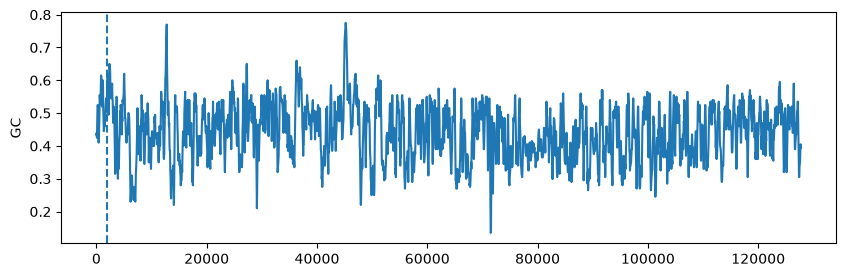

In [32]:
W, STEP = 200, 50
xs = list(range(0, len(seq) - W, STEP))
plt.figure(figsize=(10, 3))
plt.plot(xs, [gc_fraction(seq[i:i+W]) for i in xs])
plt.axvline(2000, ls="--"); plt.ylabel("GC"); plt.show()

In [33]:
def cpg_oe(s):
    s = str(s); c, g = s.count("C"), s.count("G")
    return s.count("CG") * len(s) / (c * g)
print(cpg_oe(seq[:2500]), cpg_oe(seq))

0.5820583483797396 0.31728868845522346


In [34]:
r = requests.get(f"{ENS}/sequence/id/ENST00000357654",
                 params={"type": "cds", "content-type": "text/x-fasta"})
cds = SeqIO.read(io.StringIO(r.text), "fasta").seq
prot = cds.translate(to_stop=True)
print(len(cds), len(prot), prot[:20])  # expect 1863 aa, starting MDLSALRVEE
print(f"coding share of gene: {len(cds) / (len(seq) - 2000):.1%}")

5592 1863 MDLSALRVEEVQNVINAMQK
coding share of gene: 4.4%


In [42]:
!pip install pysam
import pysam
url = "https://ftp.ncbi.nlm.nih.gov/pub/clinvar/vcf_GRCh38/clinvar.vcf.gz"
src = pysam.VariantFile(url)
with pysam.VariantFile(FILE_LOCATION_VCF, "w", header=src.header) as out:
    for rec in src.fetch("17", 43044294, 43125483):  # 0-based start
        out.write(rec)

In [43]:
from collections import Counter
from cyvcf2 import VCF
c = Counter()
for v in VCF(FILE_LOCATION_VCF):
    c[v.INFO.get("CLNSIG")] += 1
    if str(v.INFO.get("RS")) == "80357914":
        print(v.CHROM, v.POS, v.REF, v.ALT, v.INFO.get("CLNSIG"))
c.most_common(8)

17 43124027 A ['ACT'] Pathogenic
17 43124027 ACT ['A'] Pathogenic


[('Pathogenic', 3613),
 ('Conflicting_classifications_of_pathogenicity', 2924),
 ('Likely_benign', 2919),
 ('Uncertain_significance', 2492),
 (None, 2016),
 ('Benign', 704),
 ('Likely_pathogenic', 276),
 ('Pathogenic/Likely_pathogenic', 228)]